In [190]:
import numpy as np
import random
import torch
import torch.nn.functional as f
import matplotlib.pyplot as plt
print('Alert:2')

Alert:2


In [191]:
#read in all the words
words = open('names.txt','r').read().splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [192]:
n = len(words)

In [193]:
#build the vocabulary of charecter and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}


In [194]:
#build the data set
block_size =3 # context length: how many charecters do we take to predict
x,y = [],[]

for w in words:
    # print(w) 
    context =[0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        x.append(context)
        y.append(ix)
        # print(''.join(itos[i] for i in context),'----->',itos[ix])
        context = context[1:] + [ix]
x = torch.tensor(x)
y = torch.tensor(y)

In [195]:
x.shape

torch.Size([228146, 3])

In [196]:
y.shape

torch.Size([228146])

In [197]:
c = torch.randn((27,2))


In [198]:
c[x].shape

torch.Size([228146, 3, 2])

In [199]:
x[13,2]

tensor(1)

In [241]:
emb = c[x]
emb.shape

NameError: name 'xs' is not defined

In [242]:
w1 = torch.randn((6,100))
b1 = torch.randn(100)

In [239]:
h = torch.tanh(emb.view(-1,6) @ w1 + b1)
h.shape

torch.Size([22655, 300])

In [203]:
# torch.cat([emb[:,0,:],emb[:,1,:],emb[:,2,:]],1).shape

In [204]:
# torch.cat(torch.unbind(emb,1),1).shape

In [205]:
w2 = torch.randn((100,27))
b2 = torch.randn(27)

In [206]:
logits = h @ w2 + b2
logits.shape

torch.Size([228146, 27])

In [207]:
counts = logits.exp()
prob = counts / counts.sum(1,keepdim=True)

In [208]:
prob.shape

torch.Size([228146, 27])

In [209]:
# loss=-prob[torch.arange(32),y].log().mean()
# loss

In [210]:
#----now made it respectable ---------

In [211]:
x.shape,y.shape # dataset

(torch.Size([228146, 3]), torch.Size([228146]))

In [212]:
g = torch.Generator().manual_seed(2147483647)# for reproducibility
c = torch.randn((27,2),generator = g)
w1 = torch.randn((6,100),generator = g)
b1 = torch.randn(100,generator = g)
w2 = torch.randn((100,27),generator=g)
b2 = torch.randn(27,generator = g)
parameters = [c,w1,b1,w2,b2]

In [213]:
sum(p.nelement() for p in parameters)

3481

In [214]:
for p in parameters:
    p.requires_grad =True

In [215]:

# # forward pass
# for _ in range(1000):
#     emb = c[x]
#     h = torch.tanh(emb.view(-1,6) @ w1+b1)
#     logits = h@ w2 + b2
#     loss = f.cross_entropy(logits,y)
#     # backward pass
#     for p in parameters:
#         p.grad =None
#     loss.backward()
#     #update
    
#     for p in parameters:
#         p.data += -0.1*p.grad

# print(loss.item())

In [216]:
# counts = logits.exp()
# prob = counts/counts.sum(1,keepdims=True)
# loss = -prob[torch.arange(32),y].log().mean()
lre = torch.linspace(-3,0,1000)
lrs = 10**lre

In [217]:
# forward pass
# minibatch
lr1 = []
loss1 = []

for i in range(1000):
    ix = torch.randint(0,x.shape[0],(32,))
    emb = c[x[ix]]
    h = torch.tanh(emb.view(-1,6) @ w1+b1)
    logits = h@ w2 + b2
    loss = f.cross_entropy(logits,y[ix])
    # backward pass
    for p in parameters:
        p.grad =None
    loss.backward()
    lr = lrs[i]
    #update
    for p in parameters:
        p.data += -lr*p.grad
    # track
    lr1.append(lre[i])
    loss1.append(loss.item())

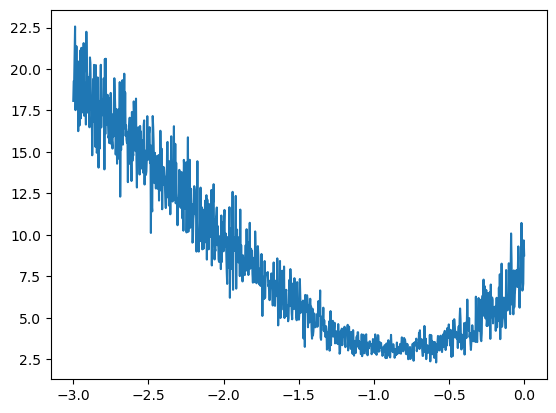

In [218]:
plt.plot(lr1,loss1)

In [219]:
len(lre)

1000

In [220]:
# build the dataset
def build_dataset(words):
    block_size = 3 # context length:how many character do we to predict the next
    x,y = [],[]
    for w in words:
        #printW)
        context = [0] * block_size
        for ch in w+'.':
            ix = stoi[ch]
            x.append(context)
            y.append(ix)

            context = context[1:] +[ix]
    x = torch.tensor(x)
    y = torch.tensor(y)

    print(x.shape,y.shape)
    return x,y



random.seed(42)
random.shuffle(words)
n1 = int(n*0.8)
n2 = int(n*0.9)

xtr,ytr = build_dataset(words[:n1])
xdev,ydev = build_dataset(words[n1:n2])
xte,yte = build_dataset(words[n2:])
    

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [221]:
c = torch.randn((27,2))


In [222]:
emb = c[x]
emb.shape

torch.Size([228146, 3, 2])

In [223]:
g = torch.Generator().manual_seed(2147483647)# for reproducibility
c = torch.randn((27,2),generator = g)
w1 = torch.randn((6,300),generator = g)
b1 = torch.randn(300,generator = g)
w2 = torch.randn((300,27),generator=g)
b2 = torch.randn(27,generator = g)
parameters = [c,w1,b1,w2,b2]

In [224]:
sum(p.nelement() for p in parameters)
xtr.shape,ytr.shape

(torch.Size([182625, 3]), torch.Size([182625]))

In [225]:
for p in parameters:
    p.requires_grad =True

In [233]:
# forward pass
lre = torch.linspace(-3,0,1000)
lrs = 10**lre
# minibatch
lr1 = []
loss1 = []
step1 = []

for i in range(3000):
    ix = torch.randint(0,xtr.shape[0],(32,))
    emb = c[xtr[ix]]
    h = torch.tanh(emb.view(-1,6) @ w1+b1)
    logits = h@ w2 + b2
    loss = f.cross_entropy(logits,ytr[ix])
    # backward pass
    for p in parameters:
        p.grad =None
    loss.backward()
    lr = 0.01
    #update
    for p in parameters:
        p.data += -lr*p.grad
    # track
    # lr1.append(lre[i])
    step1 .append(i)
    loss1.append(loss.item())
    
loss.item()  

2.3885953426361084

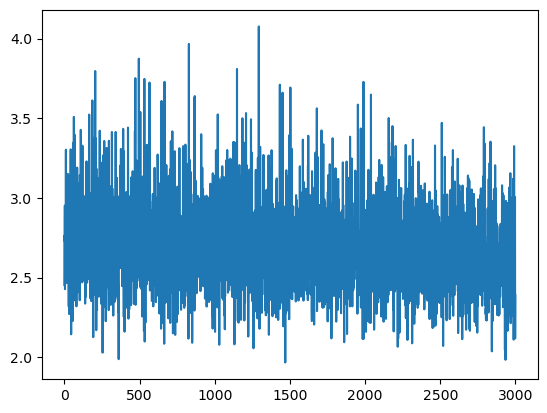

In [234]:
plt.plot(step1,loss1)

In [235]:
emb = c[xdev]
h = torch.tanh(emb.view(-1,6)@w1+ b1)
logits = h@w2 +b2
loss = f.cross_entropy(logits,ydev)
loss.item()

2.6167800426483154

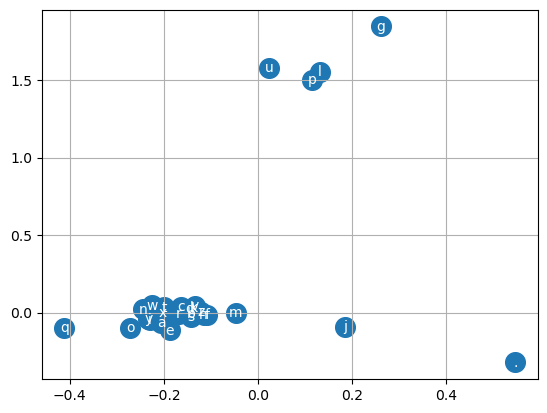

In [237]:
plt.scatter(
    c[:,0].detach(),
    c[:,1].detach(),
    s=200
)

for i in range(c.shape[0]):
    plt.text(
        c[i,0].detach().item(),
        c[i,1].detach().item(),
        itos[i],
        ha='center',
        va='center',
        color='white'
    )
plt.grid('minor')
plt.show()